# Step 11 — Daily waveform counts and station availability

This notebook contains the complete step-11 analysis and plotting code. Only shared configuration is imported; no step-specific Python module is needed.

Run after step 10. It reads the saved waveform index and verified trace-ID provenance, writes CSV summaries and four PNG figures into the configured external QC directory, and leaves waveform files unchanged. Existing step-11 products with the same names are replaced.

**Interpretation:** counts describe surviving triggered recordings, not total earthquakes or continuous uptime. A station is present on a day if at least one indexed recording contains it. Blank days mean no indexed recording, not necessarily a failed instrument. Daily bins use recorded start-date labels; parsing as UTC is a computational convention, not validation of historical clock offsets. An event spanning midnight is assigned to its start day.

All days between the first and last indexed start date are included. Daily bars occupy exactly one day and touch on consecutive dates. Output filenames retain the historical `10_` prefix for compatibility.

## 1. Configuration and imports

Choose a configuration file if needed, then inspect the resolved paths. This cell only loads settings; subsequent cells write the figures and tables.

In [5]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
from IPython.display import display, Image
_candidates = [Path.cwd(), Path.cwd() / '10_conversion', *Path.cwd().parents]
PIPELINE_DIR = next((p for p in _candidates if (p / 'pinatubo_steps').is_dir()), None)
if PIPELINE_DIR is None:
    raise FileNotFoundError('Start in the repository root or 10_conversion.')
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))
from pinatubo_steps.config import pipeline_paths
CONFIG_FILE = None
P = pipeline_paths(config_file=CONFIG_FILE)
WAVEFORM_INDEX = Path(P['WAVEFORM_INDEX'])
PROVENANCE = Path(P['FAIR_META_DIR']) / '10_trace_id_provenance.csv'
OUTDIR = Path(P['QC_DIR'])
FIG_DPI = 150
print('Configuration:', P['CONFIG_FILE'])
print('Waveform index:', WAVEFORM_INDEX)
print('Trace provenance:', PROVENANCE)
print('Output directory:', OUTDIR)

Configuration: /Users/thompsong/Developer/Pinatubo1991SeismicData/10_conversion/conversion_config.json
Waveform index: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/10_waveform_index.csv
Trace provenance: /Users/thompsong/work/Pinatubo1991Processing/converted/FAIR/metadata/10_trace_id_provenance.csv
Output directory: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc


## 2. Load and validate the waveform index

Count distinct saved waveform paths, rather than duplicate index rows. Invalid start times are reported and excluded. Reindexing to a complete daily calendar preserves gaps in both the bar charts and heatmap. Review any duplicate or invalid rows before treating these products as final.

In [6]:
df = pd.read_csv(WAVEFORM_INDEX, low_memory=False)
required = {'dmx_file', 'wav_file', 'starttime', 'stations'}
if not required.issubset(df.columns):
    raise ValueError(f'Missing index columns: {sorted(required - set(df.columns))}')
df['starttime'] = pd.to_datetime(df['starttime'], utc=True, errors='coerce', format='mixed')
invalid = df[df['starttime'].isna() | df['wav_file'].isna()].copy()
print('Excluded rows with missing path or invalid start time:', len(invalid))
display(invalid.head())
df = df.drop(index=invalid.index).copy()
print('Duplicate saved-waveform rows:', df.duplicated('wav_file').sum())
df = df.drop_duplicates('wav_file').copy()
if df.empty:
    raise ValueError('No valid waveform records to plot.')
df['date'] = df['starttime'].dt.normalize()
days = pd.date_range(df['date'].min(), df['date'].max(), freq='D', name='date')
OUTDIR.mkdir(parents=True, exist_ok=True)
invalid.to_csv(OUTDIR / '11_invalid_waveform_index_rows.csv', index=False)
wf_per_day = df.groupby('date').size().reindex(days, fill_value=0).rename('n_waveforms')
print(f'{len(df):,} saved files across {len(days)} calendar days.')

Excluded rows with missing path or invalid start time: 0


,event_id,dmx_file,wav_file,starttime,endtime,stations,channels,ntraces,status


Duplicate saved-waveform rows: 0
21,449 saved files across 220 calendar days.


## 3. Count stations and actual SEED IDs

Station presence comes from the index's saved station list. SEED IDs come from step-10 provenance joined by raw input path to successfully indexed files, using only `written`/`existing` entries. Never take a Cartesian product of separate station/channel lists: it would invent combinations.

If provenance is absent or incomplete for an indexed file, read that saved MiniSEED file's headers instead. This fallback can take time on cloud-backed files. A failed fallback stops the notebook rather than publishing an understated count. No sample arrays are needed for this header-only MiniSEED read.

In [7]:
df_sta = df[['date', 'stations']].copy()
df_sta['station'] = df_sta['stations'].fillna('').str.split(',')
df_sta = df_sta.explode('station')
df_sta['station'] = df_sta['station'].str.strip()
df_sta = df_sta[df_sta['station'].ne('')]
stations_per_day = df_sta.groupby('date')['station'].nunique().reindex(days, fill_value=0).rename('n_stations')
seed_rows = []
verified = {}
if PROVENANCE.is_file():
    provenance = pd.read_csv(PROVENANCE, low_memory=False)
    needed = {'dmx_file', 'fixed_id', 'status'}
    if not needed.issubset(provenance.columns):
        raise ValueError(f'Invalid provenance columns: {PROVENANCE}')
    good = provenance[provenance['status'].isin(['written', 'existing'])].dropna(subset=['fixed_id'])
    verified = good.groupby('dmx_file')['fixed_id'].agg(lambda s: sorted(set(s))).to_dict()
fallback_count = 0
for row in df.itertuples(index=False):
    ids = verified.get(row.dmx_file, [])
    if not ids:
        from obspy import read
        ids = sorted({tr.id for tr in read(str(row.wav_file), headonly=True)})
        fallback_count += 1
    seed_rows.extend({'date': row.date, 'seed_id': seed_id} for seed_id in ids)
df_seed = pd.DataFrame(seed_rows, columns=['date', 'seed_id'])
seed_per_day = df_seed.groupby('date')['seed_id'].nunique().reindex(days, fill_value=0).rename('n_seed_ids')
avail = (df_sta.groupby(['date', 'station']).size().unstack(fill_value=0)
         .reindex(days, fill_value=0).gt(0).sort_index(axis=1))
if avail.empty or not len(avail.columns):
    raise ValueError('No station labels available for the availability plot.')
print('Files requiring MiniSEED header fallback:', fallback_count)
display(pd.concat([wf_per_day, stations_per_day, seed_per_day], axis=1).head())

Files requiring MiniSEED header fallback: 0


,n_waveforms,n_stations,n_seed_ids
date,,,
1991-05-01 00:00:00+00:00,24,3,3
1991-05-02 00:00:00+00:00,6,3,3
1991-05-03 00:00:00+00:00,32,3,3
1991-05-04 00:00:00+00:00,74,4,4
1991-05-05 00:00:00+00:00,40,4,4


## 4. Save daily tables and full-width bar charts

Bars begin at midnight on each recorded day and have a width of exactly one day, with no outlines or spacing. Zero-count days remain visible as gaps. Each chart uses the same full calendar range.

In [8]:
plot_paths = []
def format_dates(ax):
    locator = mdates.AutoDateLocator(minticks=5, maxticks=12)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_xlim(days[0], days[-1] + pd.Timedelta(days=1))
    ax.set_xlabel('Recorded start date (clock convention not independently verified)')

for series, stem, title, ylabel in [
    (wf_per_day, '10_waveform_files_per_day', 'Saved waveform files per day', 'Waveform files'),
    (stations_per_day, '10_stations_per_day', 'Stations represented in triggered files per day', 'Stations'),
    (seed_per_day, '10_seed_ids_per_day', 'Verified SEED IDs represented per day', 'SEED IDs'),
]:
    series.to_csv(OUTDIR / (stem + '.csv'))
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(series.index, series.values, width=1.0, align='edge', linewidth=0, color='tab:blue')
    format_dates(ax)
    ax.set(title=title, ylabel=ylabel)
    ax.set_ylim(bottom=0)
    ax.yaxis.get_major_locator().set_params(integer=True)
    fig.tight_layout()
    path = OUTDIR / (stem + '.png')
    fig.savefig(path, dpi=FIG_DPI)
    plt.close(fig)
    plot_paths.append(path)

## 5. Save the station-presence heatmap

Black indicates at least one indexed recording that day; white indicates none. Each column is a complete calendar day, including days with no files anywhere in the archive. This is daily presence, not the fraction of the day recorded.

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/10_waveform_files_per_day.png


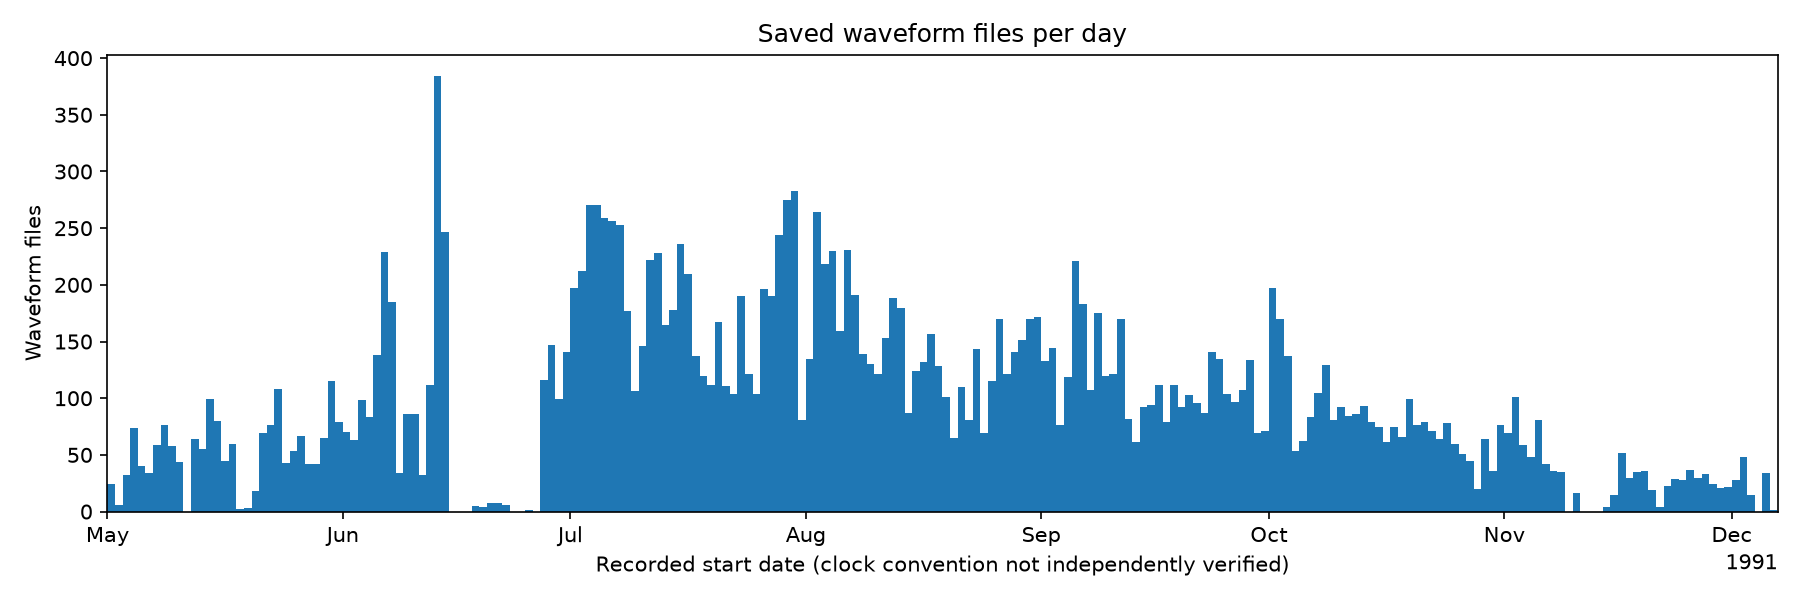

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/10_stations_per_day.png


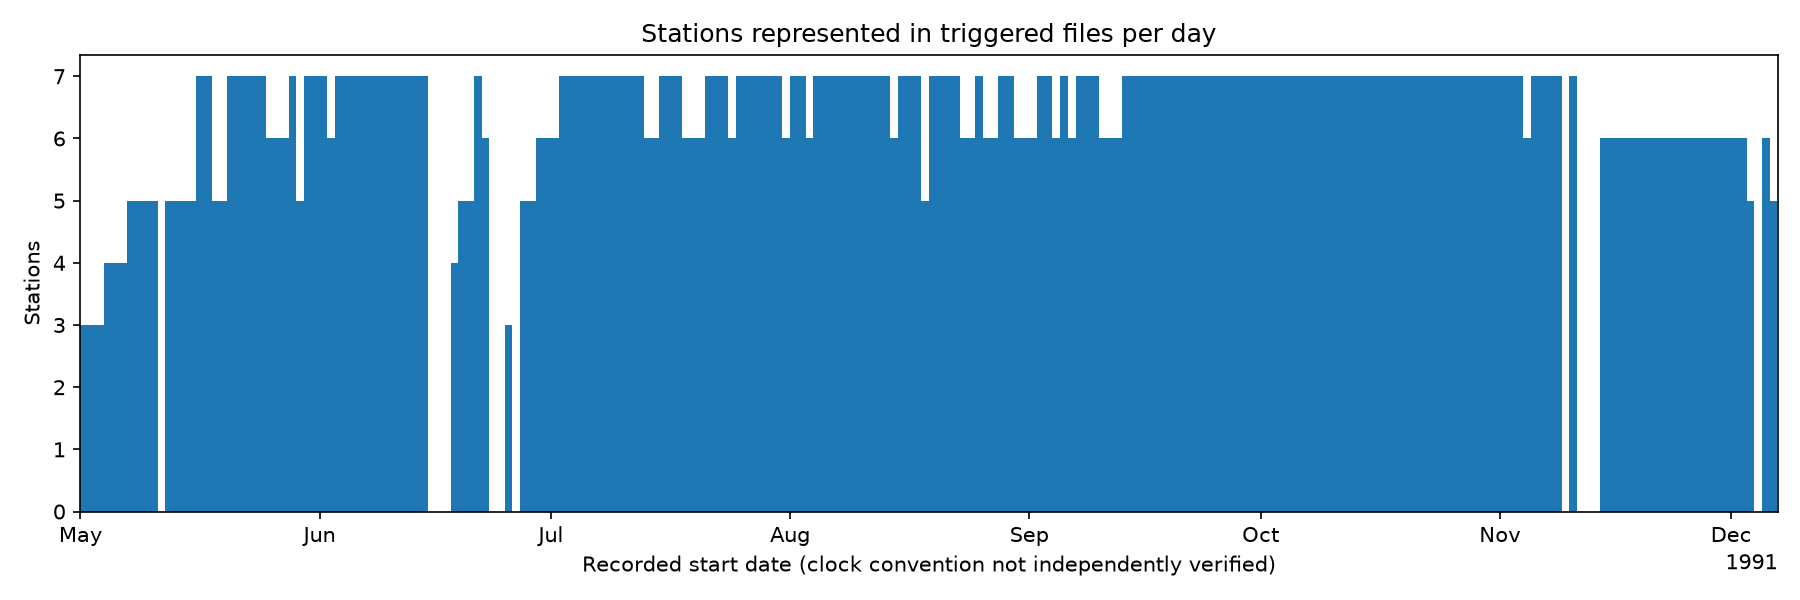

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/10_seed_ids_per_day.png


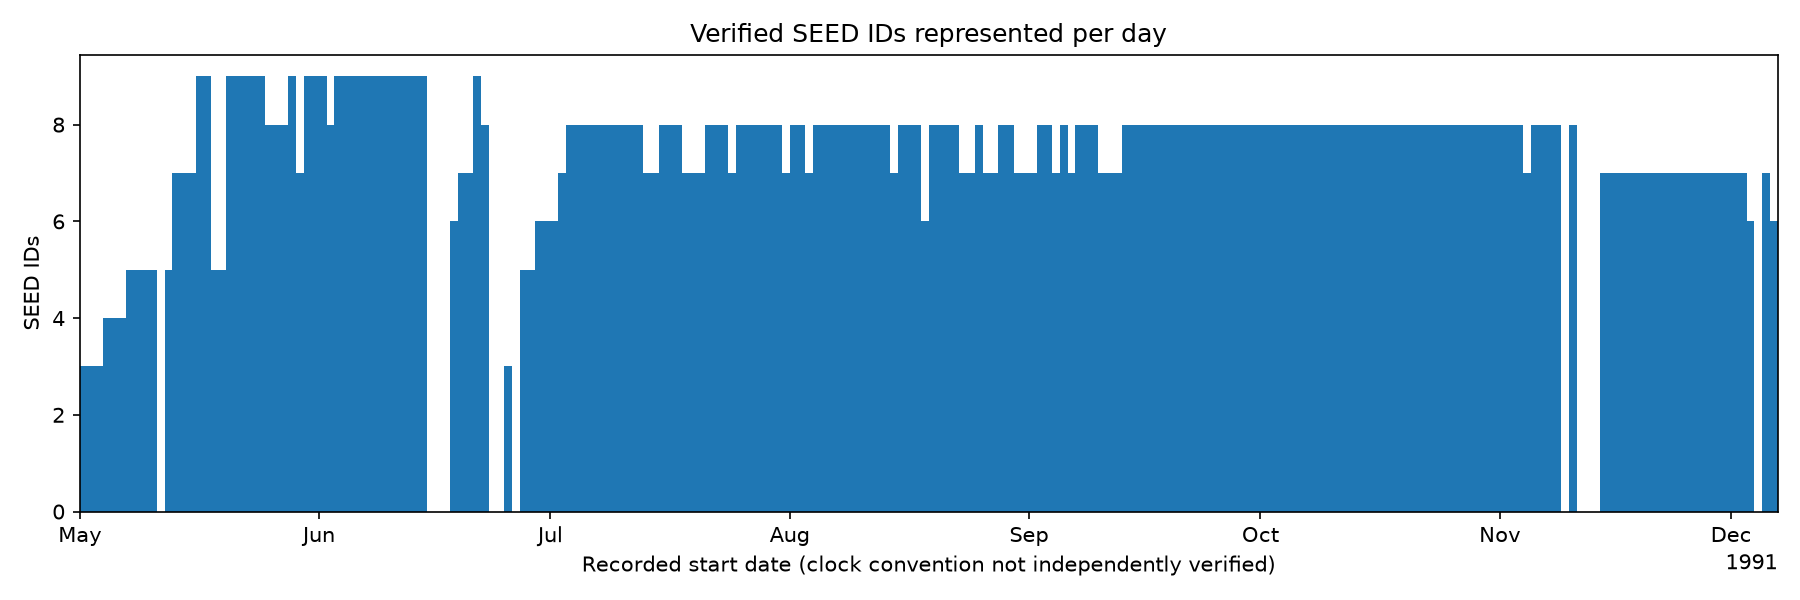

/Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/qc/10_station_availability.png


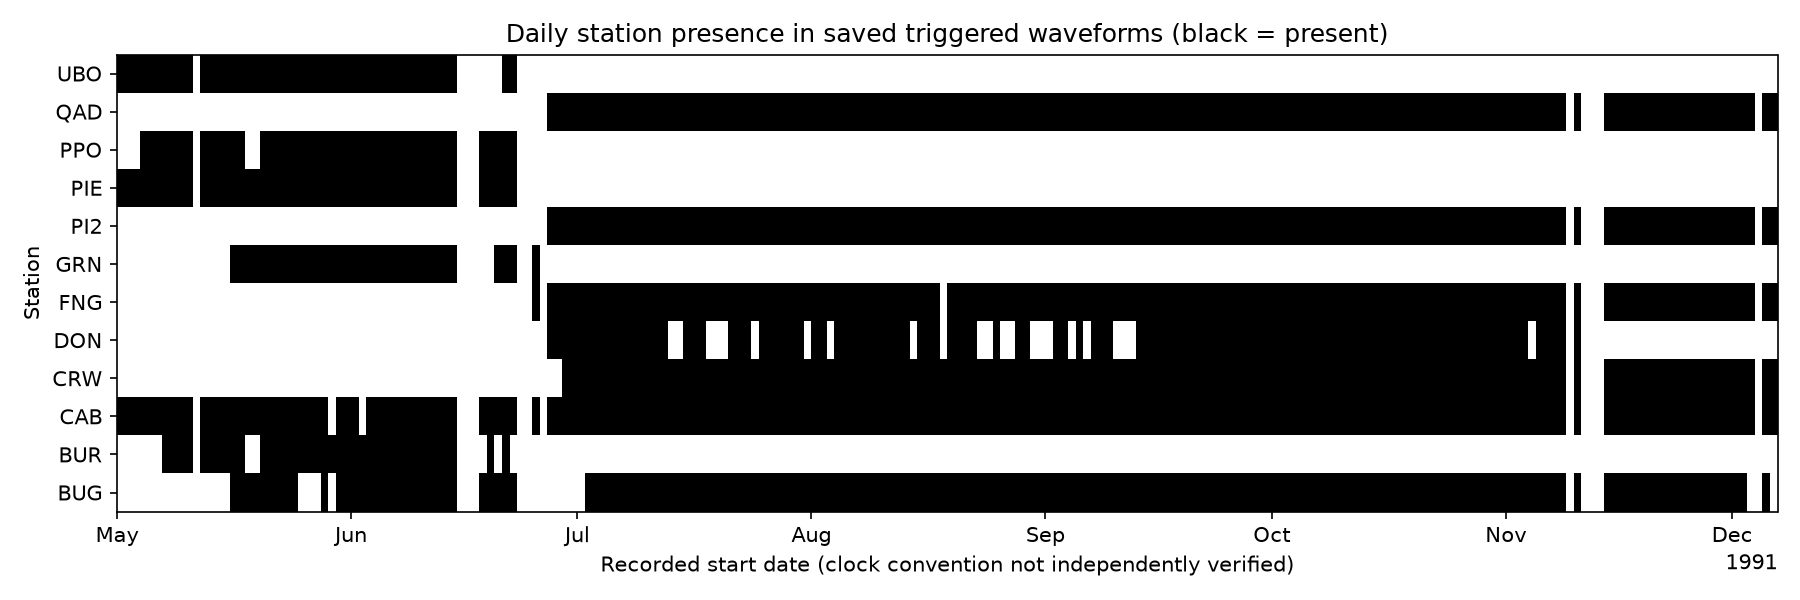

Step 11 complete. Continue with step 15 for network history and StationXML.


In [9]:
avail.to_csv(OUTDIR / '10_station_availability_matrix.csv')
fig, ax = plt.subplots(figsize=(12, max(4, 0.3 * len(avail.columns))))
left = mdates.date2num(days[0].to_pydatetime())
right = mdates.date2num((days[-1] + pd.Timedelta(days=1)).to_pydatetime())
ax.imshow(avail.T.to_numpy(dtype=int), aspect='auto', interpolation='nearest',
          origin='lower', cmap=ListedColormap(['white', 'black']), vmin=0, vmax=1,
          extent=(left, right, -0.5, len(avail.columns) - 0.5))
ax.set_yticks(range(len(avail.columns)), labels=avail.columns)
ax.xaxis_date()
format_dates(ax)
ax.set(ylabel='Station', title='Daily station presence in saved triggered waveforms (black = present)')
fig.tight_layout()
path = OUTDIR / '10_station_availability.png'
fig.savefig(path, dpi=FIG_DPI)
plt.close(fig)
plot_paths.append(path)
for path in plot_paths:
    print(path)
    display(Image(filename=str(path)))
print('Step 11 complete. Continue with step 15 for network history and StationXML.')